# The AXIOM knowledge graph — what is actually in it

Exploratory analysis of the delivered export, and nothing else. No engine, no waterfall, no models — just the data: what arrived, how much of it, how it connects, what is missing, and what the numbers look like.

Everything here is read straight off the file. If a statement is made below, the cell above it is the evidence.

**Run it from the repository root:**

```
jupyter lab notebooks/03_axiom_graph_eda.ipynb
```

**Contents**

1. The file, and its shape
2. How the pieces connect
3. Table by table — rows, columns, what is blank
4. Keys and referential integrity
5. Time — what period this covers
6. Money — currencies
7. The order book — orders, lines, products, customers
8. **Depth** — how much data sits behind any one thing
9. Prices and discounts
10. Quantities
11. Price components — the anatomy of a concession
12. The sales funnel — enquiries, quotes, outcomes
13. **The price experiment hiding in the quotes**
14. **Does anything respond to price?**
15. What this dataset is

In [1]:
import sys, json, math, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 120)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from pricing.graph.json_source import GraphJsonSource
from pricing.profiles import AXIOM_POC

EXPORT = ROOT.parent / "axiom_pricing_module_Knowledge-graph_PoC.json"
src = GraphJsonSource(export=EXPORT, profile=AXIOM_POC)
doc = src.document

print(f"file:  {EXPORT.name}")
print(f"size:  {EXPORT.stat().st_size / 1e6:,.1f} MB")
for key in ("session_label", "exported_at", "includes_internal_properties"):
    print(f"{key + ':':<30} {doc.get(key)}")
print(f"{'summary:':<30} {doc.get('summary')}")

file:  axiom_pricing_module_Knowledge-graph_PoC.json
size:  3.2 MB
session_label:                 _S_402e0f56_a2b1_459c_af3f_fc80e3b682cb
exported_at:                   2026-09-10T17:10:42.785660+00:00
includes_internal_properties:  False
summary:                       {'complete': True, 'node_count': 5794, 'relationship_count': 7765}


In [3]:
# One place for chart styling, so every figure below reads the same way.
# Colours are the first three slots of the data-viz reference palette, in their
# fixed order -- these three are the set validated for all-pairs separation,
# including for colour-vision deficiency. Slots are never cycled or reordered.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#dcdcd8"

plt.rcParams.update({
    "figure.figsize": (9, 4),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED,
    "axes.titlecolor": INK,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 12,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "font.size": 9,
    "legend.frameon": False,
})

def style(ax, title="", xlabel="", ylabel="", xgrid=False):
    """Recessive axes, one-line title, grid on the measure axis only."""
    ax.set_title(title)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.xaxis.grid(xgrid); ax.yaxis.grid(not xgrid)
    ax.tick_params(length=0)
    return ax

thousands = FuncFormatter(lambda v, _: f"{v:,.0f}")
print("chart styling ready")

chart styling ready


---
## 1. The file, and its shape

The export is a single JSON document with two lists in it: **nodes** (things) and **relationships** (links between things). Every node carries a `label` saying what kind of thing it is, and a bag of properties.

The engine treats **one label as one table** — `Order` nodes are the orders table — so counting labels is the same as counting rows per table.

In [3]:
labels = pd.Series(src.labels(), name="nodes").sort_values(ascending=False)
rels = pd.Series(
    pd.DataFrame(doc["relationships"])["type"].value_counts(), name="relationships"
)

print(f"{len(doc['nodes']):,} nodes across {len(labels)} labels")
print(f"{len(doc['relationships']):,} relationships across {len(rels)} types")
labels.to_frame()

5,794 nodes across 24 labels
7,765 relationships across 17 types


,nodes
StageChange,1412
PriceComponent,1238
Quote,1000
Opportunity,500
DealOutcome,500
OrderLine,262
CompetitorPresence,166
Order,100
CustomerPeriod,90
ListPricePeriod,80


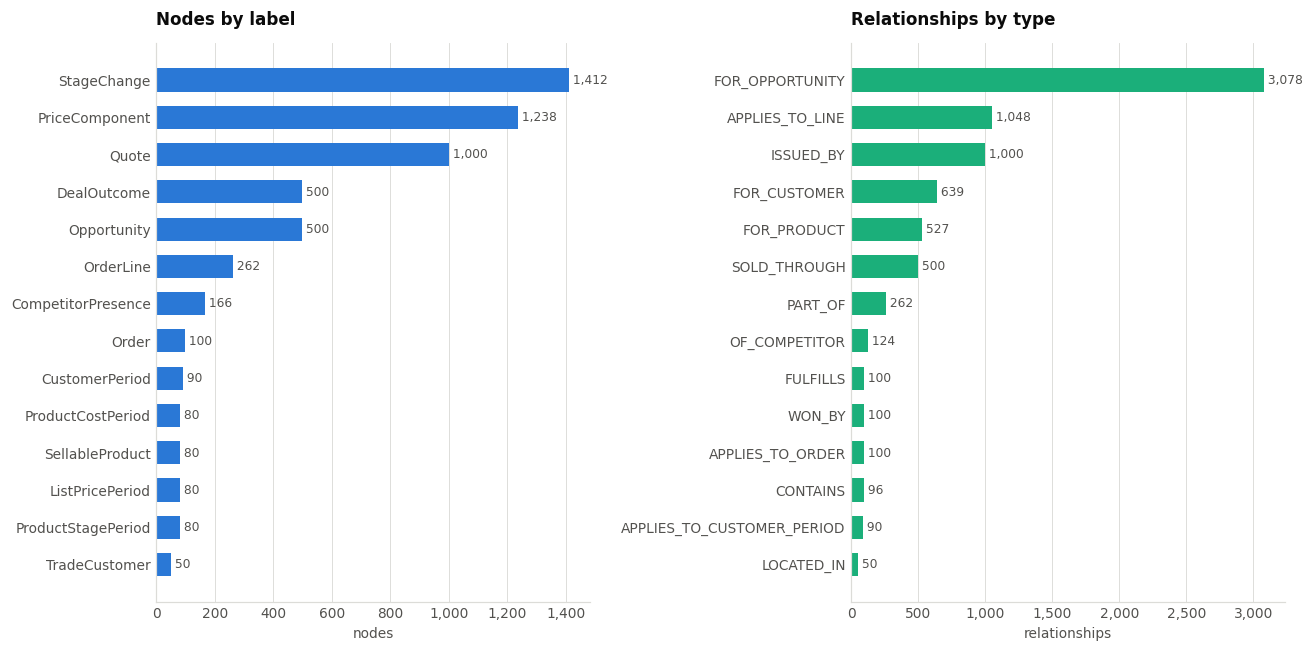

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

top = labels.head(14).sort_values()
axes[0].barh(top.index, top.values, color=BLUE, height=0.62)
style(axes[0], "Nodes by label", xlabel="nodes", xgrid=True)
axes[0].xaxis.set_major_formatter(thousands)
for y, v in enumerate(top.values):
    axes[0].text(v, y, f" {v:,}", va="center", fontsize=8, color=MUTED)

topr = rels.head(14).sort_values()
axes[1].barh(topr.index, topr.values, color=AQUA, height=0.62)
style(axes[1], "Relationships by type", xlabel="relationships", xgrid=True)
axes[1].xaxis.set_major_formatter(thousands)
for y, v in enumerate(topr.values):
    axes[1].text(v, y, f" {v:,}", va="center", fontsize=8, color=MUTED)

fig.tight_layout()
plt.show()

The proportions are the first thing worth noticing, and they set up everything that follows.

The biggest tables are about the **sales process**: 1,412 stage changes, 1,238 price components, 1,000 quotes, 500 opportunities, 500 outcomes. The **completed order book** is small: **100 orders, 262 order lines**.

So this is a graph built around how deals are negotiated, with a short record of the deals that closed hanging off the end of it.

---
## 2. How the pieces connect

In words, following one sale from enquiry to invoice:

```
TradeCustomer ──┐
                ├─ Opportunity ──┬── Quote (one per negotiating round)
Channel ────────┘                ├── DealOutcome (won / lost / withdrawn / no bid / open)
                                 ├── StageChange (movement through the sales stages)
                                 └── CompetitorPresence ── RivalSeller
                       │
                       └── Order ── OrderLine ── SellableProduct
                                        │              ├── ListPricePeriod  (price, with dates)
                                        │              ├── ProductCostPeriod (cost, with dates)
                                        │              └── ProductStagePeriod (lifecycle)
                                        │
                                   PriceComponent  (one per concession, on the line,
                                                    the order, or the customer-quarter)
```

Two details in that picture do a lot of work later.

**Prices and costs are periods, not attributes.** A product does not *have* a price; it has a price that was in force between two dates. Reading it means asking *when*.

**A concession is a node, not a column.** Every discount, freight charge and rebate is its own `PriceComponent`, and it records which step of the waterfall it belongs to, whether it was on or off the invoice, and — crucially — *what it was posted against*: a line, a whole order, or a customer's quarter.

In [4]:
edges = pd.DataFrame(doc["relationships"])
node_label = {n["id"]: n["labels"][0] for n in doc["nodes"]}
edges["from"] = edges["source"].map(node_label)
edges["to"] = edges["target"].map(node_label)

shape = (edges.groupby(["from", "type", "to"]).size()
              .rename("n").reset_index().sort_values("n", ascending=False))
print("every edge type, and what it connects:")
shape

every edge type, and what it connects:


,from,type,to,n
26,StageChange,FOR_OPPORTUNITY,Opportunity,1412
16,PriceComponent,APPLIES_TO_LINE,OrderLine,1048
25,Quote,ISSUED_BY,SalesAgent,1000
24,Quote,FOR_OPPORTUNITY,Opportunity,1000
9,Opportunity,FOR_CUSTOMER,TradeCustomer,500
11,Opportunity,SOLD_THROUGH,Channel,500
5,DealOutcome,FOR_OPPORTUNITY,Opportunity,500
14,OrderLine,PART_OF,Order,262
13,OrderLine,FOR_PRODUCT,SellableProduct,262
1,CompetitorPresence,FOR_OPPORTUNITY,Opportunity,166


---
## 3. Table by table — rows, columns, what is blank

`GraphJsonSource.table()` serves one logical table per label, typed according to the profile. A property that some nodes of a label carry and others do not becomes a blank cell — not a zero, and not a dropped column.

In [5]:
TABLES = list(AXIOM_POC.tables)


rows = []
frames = {}
for name in TABLES:
    try:
        df = src.table(name)
    except FileNotFoundError:
        rows.append({"table": name, "label": AXIOM_POC.tables[name], "rows": 0,
                     "columns": 0, "cells blank %": np.nan, "columns any blank": "MISSING"})
        continue
    frames[name] = df
    blank = df.isna().mean().mean() * 100
    empties = [c for c in df.columns if df[c].isna().any()]
    rows.append({
        "table": name, "label": AXIOM_POC.tables[name], "rows": len(df),
        "columns": df.shape[1], "cells blank %": round(blank, 1),
        "columns any blank": ", ".join(empties) if empties else "none",
    })

pd.DataFrame(rows).sort_values("rows", ascending=False).reset_index(drop=True)

,table,label,rows,columns,cells blank %,columns any blank
0,price_components,PriceComponent,1238,12,7.7,period
1,quotes,Quote,1000,14,5.7,model_suggested_price
2,opportunities,Opportunity,500,12,8.3,revises_opportunity_id
3,deal_outcomes,DealOutcome,500,7,14.3,"decided_at, winning_quote_id"
4,order_lines,OrderLine,262,8,0.0,none
5,orders,Order,100,10,0.0,none
6,customer_periods,CustomerPeriod,90,5,0.0,none
7,product_stages,ProductStagePeriod,80,5,0.0,none
8,product_costs,ProductCostPeriod,80,5,0.0,none
9,list_prices,ListPricePeriod,80,5,0.0,none


Every table the profile expects is present, and almost nothing is blank. The blanks that do exist are worth naming individually rather than reading as a percentage.

In [6]:
nulls = []
for name, df in frames.items():
    for col in df.columns:
        n = int(df[col].isna().sum())
        if n:
            nulls.append({"table": name, "column": col, "blank": n,
                          "of": len(df), "blank %": round(100 * n / len(df), 1)})

blanks = pd.DataFrame(nulls).sort_values("blank %", ascending=False)
blanks if len(blanks) else print("no blanks anywhere")

,table,column,blank,of,blank %
1,opportunities,revises_opportunity_id,498,500,99.6
0,price_components,period,1148,1238,92.7
4,deal_outcomes,winning_quote_id,400,500,80.0
2,quotes,model_suggested_price,796,1000,79.6
3,deal_outcomes,decided_at,100,500,20.0


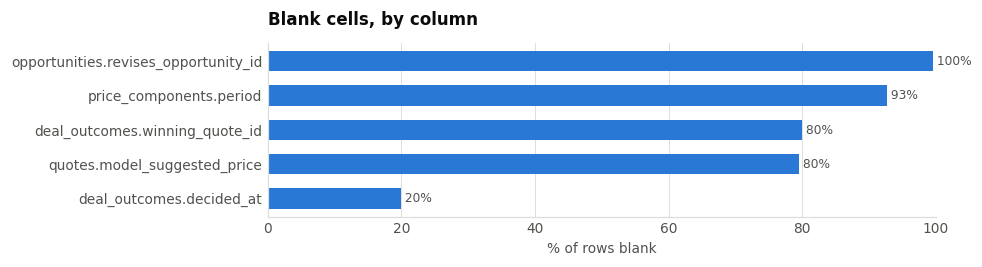

In [7]:
if len(blanks):
    fig, ax = plt.subplots(figsize=(9, max(2.5, 0.34 * len(blanks))))
    order = blanks.sort_values("blank %")
    ticks = order["table"] + "." + order["column"]
    ax.barh(ticks, order["blank %"], color=BLUE, height=0.6)
    style(ax, "Blank cells, by column", xlabel="% of rows blank", xgrid=True)
    ax.set_xlim(0, 100)
    for y, v in enumerate(order["blank %"]):
        ax.text(v, y, f" {v:.0f}%", va="center", fontsize=8, color=MUTED)
    fig.tight_layout(); plt.show()


- **`deal_outcomes.winning_quote_id` is blank 80% of the time.** That is not damage — only a *won* deal has a winning quote. 100 of the 500 outcomes are wins.
- **`quotes.model_suggested_price` is blank 80% of the time.** Same pattern: only quotes whose price came from a model carry the model's suggestion.
- **`opportunities.revises_opportunity_id`** is blank except where an enquiry supersedes an earlier one.

None of these is a missing value in the sense that matters. A field that only applies to some rows is not incomplete.

---
## 4. Keys and referential integrity

Two questions, and the second is the interesting one.

**Is every business key unique?** If `order_id` repeated, every join through it would silently multiply rows.

**Do the two copies of each foreign key agree?** This export states most links *twice* — once as a relationship, once as a property on the node. `OrderLine.order_id` sits beside `(:OrderLine)-[:PART_OF]->(:Order)`. Reading the property is cheaper, which means a disagreement between the two would produce a wrong number with a clean-looking audit trail.

In [9]:
from pricing.graph.json_source import BUSINESS_KEYS, CROSS_CHECKS

checks = []
for label, key in BUSINESS_KEYS:
    frame = src.frames.get(label)
    if frame is None or key not in frame.columns:
        continue
    checks.append({"label": label, "key": key, "rows": len(frame),
                   "distinct": frame[key].nunique(),
                   "duplicated": int(frame[key].duplicated().sum())})

pd.DataFrame(checks)

,label,key,rows,distinct,duplicated
0,Order,order_id,100,100,0
1,OrderLine,order_line_id,262,262,0
2,SellableProduct,product_id,80,80,0
3,TradeCustomer,customer_id,50,50,0
4,PriceComponent,component_id,1238,1238,0
5,Opportunity,opportunity_id,500,500,0
6,Quote,quote_id,1000,1000,0
7,Channel,channel_id,4,4,0
8,SalesAgent,agent_id,12,12,0
9,RivalSeller,competitor_id,9,9,0


In [10]:
by_type = {}
for r in doc["relationships"]:
    by_type.setdefault((node_label.get(r["source"]), r["type"]), []).append((r["source"], r["target"]))
props = {n["id"]: n.get("properties") or {} for n in doc["nodes"]}

agree = []
for src_label, edge, tgt_label, src_prop, tgt_prop in CROSS_CHECKS:
    pairs = [(s, t) for s, t in by_type.get((src_label, edge), [])
             if node_label.get(t) == tgt_label]
    if not pairs:
        continue
    bad = sum(1 for s, t in pairs if str(props[s].get(src_prop)) != str(props[t].get(tgt_prop)))
    agree.append({"property": f"{src_label}.{src_prop}",
                  "vs edge": f"-[:{edge}]->{tgt_label}.{tgt_prop}",
                  "edges": len(pairs), "disagree": bad})

checked = pd.DataFrame(agree)
print(f"{checked['edges'].sum():,} doubly-stated foreign keys checked, "
      f"{checked['disagree'].sum()} disagreements\n")
checked

7,402 doubly-stated foreign keys checked, 0 disagreements



,property,vs edge,edges,disagree
0,OrderLine.order_id,-[:PART_OF]->Order.order_id,262,0
1,OrderLine.product_id,-[:FOR_PRODUCT]->SellableProduct.product_id,262,0
2,Order.opportunity_id,-[:FULFILLS]->Opportunity.opportunity_id,100,0
3,Opportunity.customer_id,-[:FOR_CUSTOMER]->TradeCustomer.customer_id,500,0
4,Opportunity.channel_id,-[:SOLD_THROUGH]->Channel.channel_id,500,0
5,Quote.opportunity_id,-[:FOR_OPPORTUNITY]->Opportunity.opportunity_id,1000,0
6,Quote.issued_by_agent_id,-[:ISSUED_BY]->SalesAgent.agent_id,1000,0
7,DealOutcome.opportunity_id,-[:FOR_OPPORTUNITY]->Opportunity.opportunity_id,500,0
8,StageChange.opportunity_id,-[:FOR_OPPORTUNITY]->Opportunity.opportunity_id,1412,0
9,CompetitorPresence.opportunity_id,-[:FOR_OPPORTUNITY]->Opportunity.opportunity_id,166,0


In [11]:
dangling = sum(1 for r in doc["relationships"]
               if r["source"] not in node_label or r["target"] not in node_label)
stated = doc.get("summary", {})
print(f"edges pointing at a node that is not in the export : {dangling}")
print(f"export states {stated.get('node_count'):,} nodes, carries {len(doc['nodes']):,}")
print(f"export states {stated.get('relationship_count'):,} edges, carries {len(doc['relationships']):,}")
print(f"export declares itself complete                    : {stated.get('complete')}")

edges pointing at a node that is not in the export : 0
export states 5,794 nodes, carries 5,794
export states 7,765 edges, carries 7,765
export declares itself complete                    : True


The graph is internally consistent: no duplicate keys, no dangling edges, no disagreement between the two copies of any foreign key, and the counts match what the file says about itself. Structurally this is clean data.

Everything difficult about it from here on is about **how much** of it there is and **what it does not vary**, not about whether it is well-formed.

---
## 5. Time — what period this covers

In [12]:
orders = frames["orders"].copy()
lines = frames["order_lines"].copy()
opps = frames["opportunities"].copy()

print("order_date      ", orders["order_date"].min().date(), "->", orders["order_date"].max().date())
print("opportunity created", opps["created_at"].min().date(), "->", opps["created_at"].max().date())
span = orders["order_date"].dt.to_period("M")
print(f"\ncalendar months containing at least one order: {span.nunique()}")
print(f"average orders per month: {len(orders) / span.nunique():.1f}")

order_date       2025-02-26 -> 2026-10-06
opportunity created 2025-01-31 -> 2026-09-22

calendar months containing at least one order: 20
average orders per month: 5.0


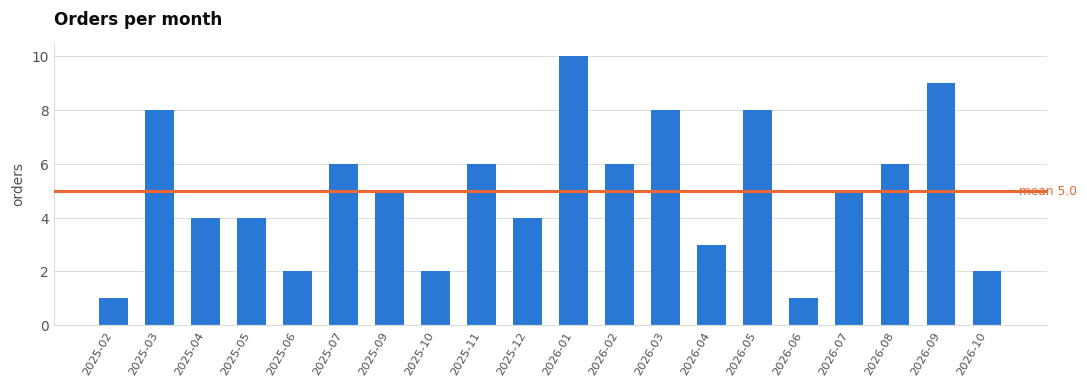

In [13]:
per_month = span.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(per_month.index.astype(str), per_month.values, color=BLUE, width=0.62)
style(ax, "Orders per month", ylabel="orders")
ax.set_xticks(range(len(per_month)))
ax.set_xticklabels(per_month.index.astype(str), rotation=60, ha="right", fontsize=7.5)
ax.axhline(per_month.mean(), color=ORANGE, lw=2, zorder=3)
ax.text(len(per_month) - 0.4, per_month.mean(), f" mean {per_month.mean():.1f}",
        color=ORANGE, va="center", fontsize=8)
fig.tight_layout(); plt.show()

Twenty months of history, averaging five orders a month. That is the whole book.

Five orders a month spread over dozens of products is the number to keep in mind for section 8 — it is what makes per-product analysis hard, and it is not something that can be fixed by processing the data differently.

---
## 6. Money — currencies

In [14]:
L = lines.merge(orders[["order_id", "currency_code", "customer_id", "order_date"]],
                on="order_id", how="left")
by_ccy = L.groupby("currency_code").agg(
    orders=("order_id", "nunique"), lines=("order_line_id", "size"),
    value=("line_value", "sum"),
)
by_ccy["value %"] = (100 * by_ccy["value"] / by_ccy["value"].sum()).round(2)
print(by_ccy.to_string())
print()
mixed = L.groupby("customer_id")["currency_code"].nunique()
print(f"customers trading in more than one currency: {(mixed > 1).sum()}")
print(f"  -> {sorted(mixed[mixed > 1].index)}")
print()
print("Is there an exchange rate anywhere in the graph?")
fx = [lbl for lbl in src.labels() if "fx" in lbl.lower() or "rate" in lbl.lower()
      or "currency" in lbl.lower()]
print(f"  labels mentioning fx / rate / currency: {fx or 'none'}")

               orders  lines       value  value %
currency_code                                    
EUR                 4     11   143898.75     2.39
SAR                96    251  5869457.86    97.61

customers trading in more than one currency: 4
  -> ['CUST0002', 'CUST0010', 'CUST0018', 'CUST0048']

Is there an exchange rate anywhere in the graph?
  labels mentioning fx / rate / currency: none


96 orders in Saudi riyal, 4 in euro, and **no exchange rate anywhere in the graph**.

The four euro orders belong to customers who *also* trade in riyal, so this is not a cleanly separable second book — it is four orders sitting inside the same customers' histories in a different unit. Any total that spans both currencies is adding two different things together, and there is nothing in this file that would let you convert one to the other.

---
## 7. The order book — orders, lines, products, customers

In [15]:
print(f"orders            {orders['order_id'].nunique():>6,}")
print(f"order lines       {len(lines):>6,}")
print(f"distinct products {lines['product_id'].nunique():>6,}  (catalogue holds {len(frames['products']):,})")
print(f"distinct customers{orders['customer_id'].nunique():>6,}  (master holds {len(frames['customers']):,})")
print()
per_order = lines.groupby("order_id").size()
print("lines per order:")
print(per_order.describe()[["min", "50%", "mean", "max"]].round(2).to_string())

orders               100
order lines          262
distinct products     78  (catalogue holds 80)
distinct customers    41  (master holds 50)

lines per order:
min     1.00
50%     3.00
mean    2.62
max     4.00


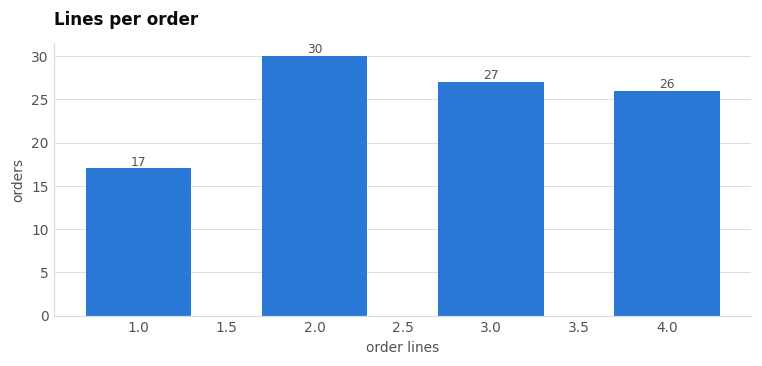

In [16]:
fig, ax = plt.subplots(figsize=(7, 3.4))
counts = per_order.value_counts().sort_index()
ax.bar(counts.index, counts.values, color=BLUE, width=0.6)
style(ax, "Lines per order", xlabel="order lines", ylabel="orders")
for x, v in counts.items():
    ax.text(x, v, f"{v}", ha="center", va="bottom", fontsize=8, color=MUTED)
fig.tight_layout(); plt.show()

---
## 8. Depth — how much data sits behind any one thing

This is the most consequential section in the notebook.

Totals are reassuring: 100 orders, 262 lines, 78 products, 41 customers. But nothing is ever estimated from *the whole book* — an elasticity is estimated per product, a customer segment from a customer's own habits. So the question that matters is not how big the book is. It is **how much evidence sits behind each thing you would want to say something about.**

In [17]:
per_product = lines.groupby("product_id").size().rename("lines")
per_customer = orders.groupby("customer_id").size().rename("orders")

print("ORDER LINES PER PRODUCT")
print(per_product.describe()[["count", "min", "50%", "mean", "max"]].round(2).to_string())
print()
print("ORDERS PER CUSTOMER")
print(per_customer.describe()[["count", "min", "50%", "mean", "max"]].round(2).to_string())

ORDER LINES PER PRODUCT
count    78.00
min       1.00
50%       3.00
mean      3.36
max       7.00

ORDERS PER CUSTOMER
count    41.00
min       1.00
50%       2.00
mean      2.44
max       6.00


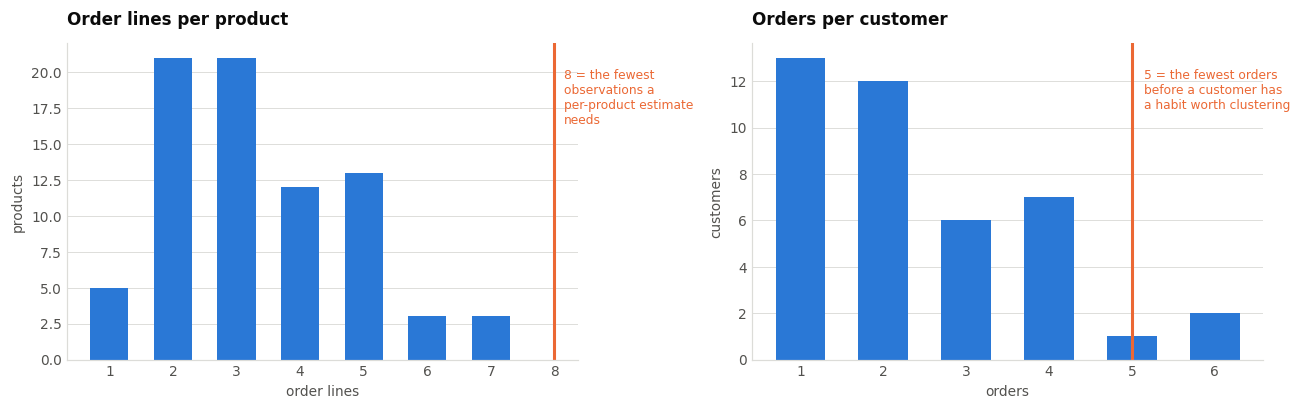

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

a = per_product.value_counts().sort_index()
axes[0].bar(a.index, a.values, color=BLUE, width=0.6)
style(axes[0], "Order lines per product", xlabel="order lines", ylabel="products")
axes[0].axvline(8, color=ORANGE, lw=2)
axes[0].text(8.15, axes[0].get_ylim()[1] * 0.92,
             "8 = the fewest\nobservations a\nper-product estimate\nneeds", color=ORANGE, fontsize=8, va="top")

b = per_customer.value_counts().sort_index()
axes[1].bar(b.index, b.values, color=BLUE, width=0.6)
style(axes[1], "Orders per customer", xlabel="orders", ylabel="customers")
axes[1].axvline(5, color=ORANGE, lw=2)
axes[1].text(5.15, axes[1].get_ylim()[1] * 0.92,
             "5 = the fewest orders\nbefore a customer has\na habit worth clustering",
             color=ORANGE, fontsize=8, va="top")

fig.tight_layout(); plt.show()

In [19]:
print(f"products bought at all                : {len(per_product):>4} of {len(frames['products'])}")
print(f"products with 8 or more order lines   : {(per_product >= 8).sum():>4}")
print(f"the most any product was bought       : {per_product.max():>4} times")
print()
print(f"customers who bought at all           : {len(per_customer):>4} of {len(frames['customers'])}")
print(f"customers with 5 or more orders       : {(per_customer >= 5).sum():>4}")
print(f"the most any customer bought          : {per_customer.max():>4} times")

products bought at all                :   78 of 80
products with 8 or more order lines   :    0
the most any product was bought       :    7 times

customers who bought at all           :   41 of 50
customers with 5 or more orders       :    3
the most any customer bought          :    6 times


**No product in the book was bought more than seven times, and most were bought two or three times.**

That single fact decides more about what this dataset can support than any other number in it. A hundred orders sounds like a small-but-workable book. Spread across 78 products it is not a book at all — it is 78 anecdotes.

The customer side is the same shape: three customers have five or more orders. Grouping customers by their buying behaviour needs customers who have exhibited behaviour.

This is a **wide and shallow** dataset — many things, each seen once or twice — and width does not substitute for depth.

---
## 9. Prices and discounts

In [20]:
products = frames["products"]
list_prices = frames["list_prices"][["product_id", "list_price", "valid_from"]]
costs = frames["product_costs"][["product_id", "unit_cost", "valid_from"]]

print("price and cost periods per product:")
print(f"  list price periods: {list_prices.groupby('product_id').size().unique()}")
print(f"  cost periods:       {costs.groupby('product_id').size().unique()}")
print(f"  all valid_from:     {sorted(list_prices['valid_from'].dt.date.unique())}")

price and cost periods per product:
  list price periods: [1]
  cost periods:       [1]
  all valid_from:     [datetime.date(2025, 1, 1)]


Worth pausing on. Prices and costs are *modelled* as periods with validity dates — but every product has exactly **one** period, all opening on the same day.

So the time dimension exists in the schema and carries no information in the data. List prices never change in this dataset. That is the second half of section 14's problem: to learn how demand responds to price, price has to move.

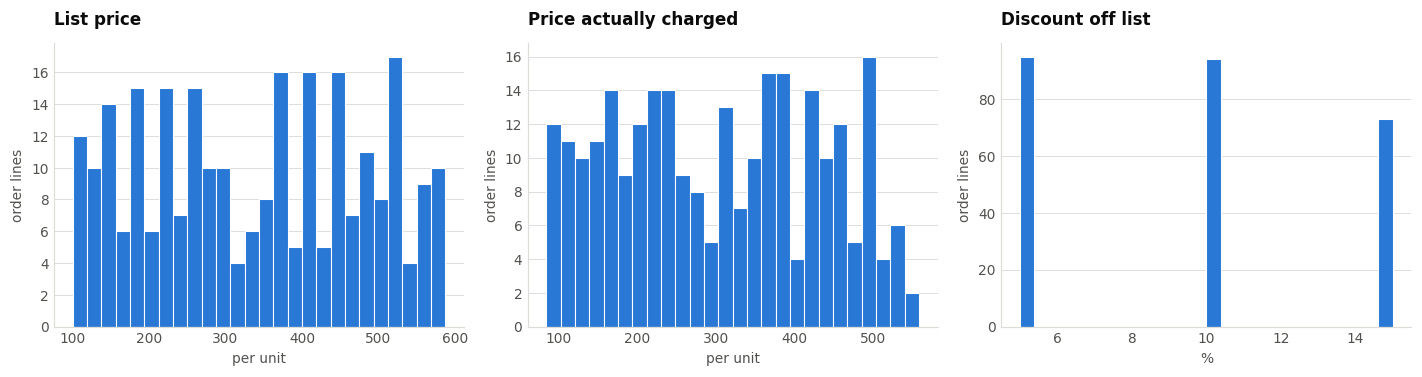

       list_price  unit_price_recorded  discount_pct  margin_pct
count      262.00               262.00        262.00      262.00
mean       334.78               302.66          9.58       31.30
std        143.46               130.30          3.99        3.06
min        100.00                85.00          5.00       27.06
25%        212.50               191.25          5.00       27.06
50%        350.00               308.44         10.00       31.11
75%        459.38               415.62         15.00       34.74
max        587.50               558.12         15.00       34.74


In [21]:
P = (lines.merge(list_prices, on="product_id", how="left")
          .merge(costs, on="product_id", how="left", suffixes=("_lp", "_c"))
          .merge(products[["product_id", "family", "grade_tier"]], on="product_id", how="left"))
P["discount_pct"] = 100 * (1 - P["unit_price_recorded"] / P["list_price"])
P["margin_pct"] = 100 * (1 - P["unit_cost"] / P["unit_price_recorded"])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col, title, unit in [
    (axes[0], "list_price", "List price", "per unit"),
    (axes[1], "unit_price_recorded", "Price actually charged", "per unit"),
    (axes[2], "discount_pct", "Discount off list", "%"),
]:
    ax.hist(P[col].dropna(), bins=26, color=BLUE, edgecolor="white", linewidth=0.7)
    style(ax, title, xlabel=unit, ylabel="order lines")
fig.tight_layout(); plt.show()

print(P[["list_price", "unit_price_recorded", "discount_pct", "margin_pct"]]
      .describe().round(2).to_string())

Look closely at that third histogram. The discount is not spread across a range — it sits in three spikes. Worth confirming exactly:

In [22]:
# Round away the cent-level rounding in the stored price, which otherwise makes
# 5% look like thirty different numbers.
levels = P["discount_pct"].round(1).value_counts().sort_index()
print("every discount level in the book:")
print(levels.rename("order lines").to_frame().to_string())
print()
distinct = P.groupby("product_id")["unit_price_recorded"].nunique()
print("how many different prices each product was ever sold at:")
print(distinct.value_counts().sort_index().rename("products").to_frame().to_string())
print()
spread = P.groupby("product_id")["unit_price_recorded"].apply(lambda x: np.log(x).std())
print("spread of log price within a product:")
print(spread.describe()[["min", "50%", "max"]].round(4).to_string())
print()
print(f"products that only ever sold at ONE price: {(distinct == 1).sum()}")

every discount level in the book:
              order lines
discount_pct             
5.0                    95
10.0                   94
15.0                   73

how many different prices each product was ever sold at:
                     products
unit_price_recorded          
1                          12
2                          44
3                          22

spread of log price within a product:
min    0.0000
50%    0.0382
max    0.0787

products that only ever sold at ONE price: 12


**Every discount in the book is 5%, 10% or 15%.** There are no other values — the handful of neighbouring numbers are just the stored price being rounded to the cent.

And so every product sold at one, two or at most three distinct prices. Twelve products never sold at more than a single price at all.

This matters more than it might look. To learn how demand responds to price you need price to *vary*, and the amount of variation sets how much you can learn. Here the variation is three fixed steps spanning ten percentage points, with a median spread of 0.038 in log terms. For the twelve single-price products there is no variation whatsoever, so no response is estimable even in principle.

In [23]:
print("discount depth by product family:")
print(P.groupby("family")["discount_pct"].describe()[["count", "mean", "50%", "min", "max"]]
       .round(2).to_string())
print()
above = P[P["unit_price_recorded"] > P["list_price"]]
print(f"lines sold ABOVE list price: {len(above)}")
print(f"lines sold below cost:       {(P['unit_price_recorded'] < P['unit_cost']).sum()}")
print(f"promotional lines:           {(P['is_promotional'].astype(str) == 'true').sum()}")

discount depth by product family:
        count   mean   50%  min   max
family                               
FAM01    41.0   9.27  10.0  5.0  15.0
FAM02    46.0   9.46  10.0  5.0  15.0
FAM03    53.0   9.24  10.0  5.0  15.0
FAM04    61.0  10.16  10.0  5.0  15.0
FAM05    27.0   9.63  10.0  5.0  15.0
FAM06    34.0   9.56  10.0  5.0  15.0

lines sold ABOVE list price: 0
lines sold below cost:       0
promotional lines:           69


---
## 10. Quantities

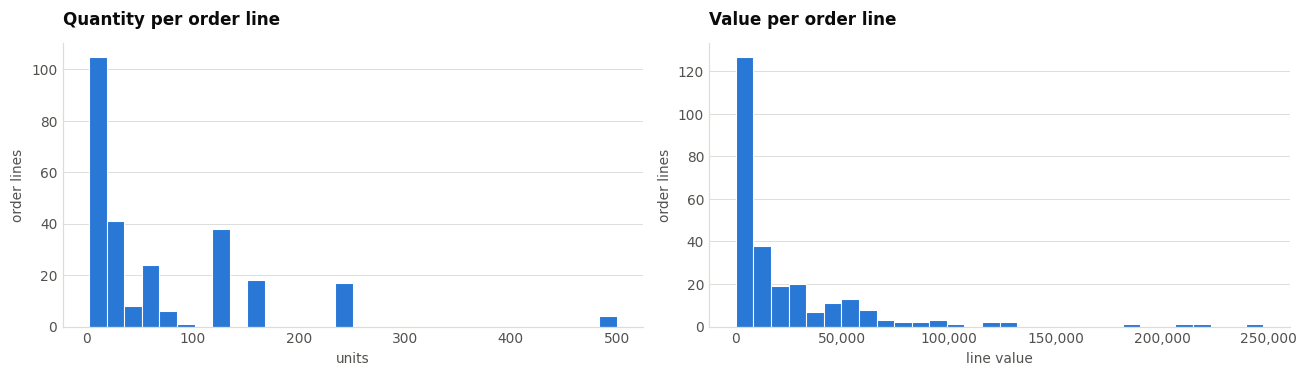

       quantity  line_value
count    262.00      262.00
mean      70.22    22951.74
std       88.92    34987.86
min        2.00      190.00
25%        8.00     2119.68
50%       25.00     8722.25
75%      125.00    29687.88
max      500.00   247500.00


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(P["quantity"].dropna(), bins=30, color=BLUE, edgecolor="white", linewidth=0.7)
style(axes[0], "Quantity per order line", xlabel="units", ylabel="order lines")

axes[1].hist(P["line_value"].dropna(), bins=30, color=BLUE, edgecolor="white", linewidth=0.7)
style(axes[1], "Value per order line", xlabel="line value", ylabel="order lines")
axes[1].xaxis.set_major_formatter(thousands)
fig.tight_layout(); plt.show()

print(P[["quantity", "line_value"]].describe().round(2).to_string())

---
## 11. Price components — the anatomy of a concession

Every concession is its own node, and it records three things that matter: which waterfall step it belongs to, whether it was on or off the invoice, and **what it was posted against**.

That last one is the whole ballgame for what can be reported at what level of detail.

In [25]:
pc = frames["price_components"]
anatomy = (pc.groupby(["step_name", "step_type", "applies_to_level", "on_invoice"])
             .agg(components=("component_id", "size"), total=("amount", "sum"))
             .reset_index())
anatomy["total"] = anatomy["total"].round(2)
anatomy

,step_name,step_type,applies_to_level,on_invoice,components,total
0,freight,deduction,line,true,87,-56790.47
1,freight,deduction,order,true,100,-21143.52
2,invoice_discount,deduction,line,true,262,-244706.71
3,list_price,level,line,true,262,6677812.50
4,payment_discount,deduction,line,false,175,-156406.47
5,volume_rebate,deduction,customer_period,false,90,-80032.65
6,volume_rebate,deduction,line,false,262,-229560.74


In [26]:
grain = pc.groupby("applies_to_level").agg(
    components=("component_id", "size"), total=("amount", "sum")).round(2)
print(grain.to_string())
print()
print("What each grain means for reporting:")
print("  line            posted against one product on one order -- reportable anywhere")
print("  order           posted once for a whole order (freight) -- cannot be split")
print("                  across the products on it without inventing a split")
print("  customer_period posted against a customer's QUARTER -- spans orders that are")
print("                  not all in this book at all")

                  components       total
applies_to_level                        
customer_period           90   -80032.65
line                    1048  5990348.11
order                    100   -21143.52

What each grain means for reporting:
  line            posted against one product on one order -- reportable anywhere
  order           posted once for a whole order (freight) -- cannot be split
                  across the products on it without inventing a split
  customer_period posted against a customer's QUARTER -- spans orders that are
                  not all in this book at all


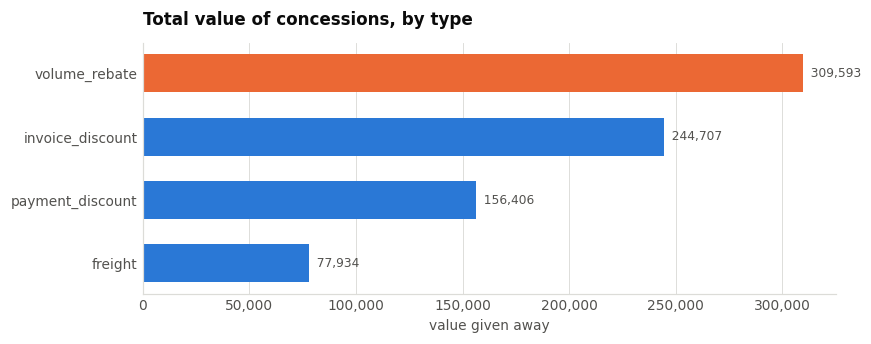

volume rebates posted against a customer-quarter: 90 worth -80,032.65
of which marked as an estimate (an accrual, not a posting): 90


In [27]:
deductions = pc[pc["step_type"] == "deduction"].copy()
by_step = deductions.groupby("step_name")["amount"].sum().abs().sort_values()

fig, ax = plt.subplots(figsize=(8, 3.2))
colors = [ORANGE if s == "volume_rebate" else BLUE for s in by_step.index]
ax.barh(by_step.index, by_step.values, color=colors, height=0.6)
style(ax, "Total value of concessions, by type", xlabel="value given away", xgrid=True)
ax.xaxis.set_major_formatter(thousands)
for y, v in enumerate(by_step.values):
    ax.text(v, y, f"  {v:,.0f}", va="center", fontsize=8, color=MUTED)
fig.tight_layout(); plt.show()

quarterly = deductions[deductions["applies_to_level"] == "customer_period"]
print(f"volume rebates posted against a customer-quarter: {len(quarterly)} "
      f"worth {quarterly['amount'].sum():,.2f}")
print(f"of which marked as an estimate (an accrual, not a posting): "
      f"{(quarterly['is_estimated'].astype(str) == 'true').sum()}")

The orange bar is the awkward one. Those quarterly volume rebates are real money — around 80,000 — but they are attached to a **customer's quarter**, and a quarter contains orders that are not in this hundred.

There is no honest way to say how much of that rebate belongs to any single order. You can report it beside the order book; you cannot report it inside it.

---
## 12. The sales funnel — enquiries, quotes, outcomes

This is the part of the graph that is *not* small, and it is where most of the information in the file lives.

In [28]:
quotes = frames["quotes"]
outcomes = frames["deal_outcomes"]

print(f"opportunities (enquiries) {len(opps):>6,}")
print(f"quotes issued             {len(quotes):>6,}   ({len(quotes) / len(opps):.1f} per enquiry)")
print(f"outcomes recorded         {len(outcomes):>6,}")
print(f"became an order           {orders['opportunity_id'].nunique():>6,}")
print()
print(outcomes["result"].value_counts().to_frame("outcomes").to_string())

opportunities (enquiries)    500
quotes issued              1,000   (2.0 per enquiry)
outcomes recorded            500
became an order              100

                    outcomes
result                      
lost_to_competitor       101
open                     100
won                      100
customer_withdrew        100
no_bid                    99


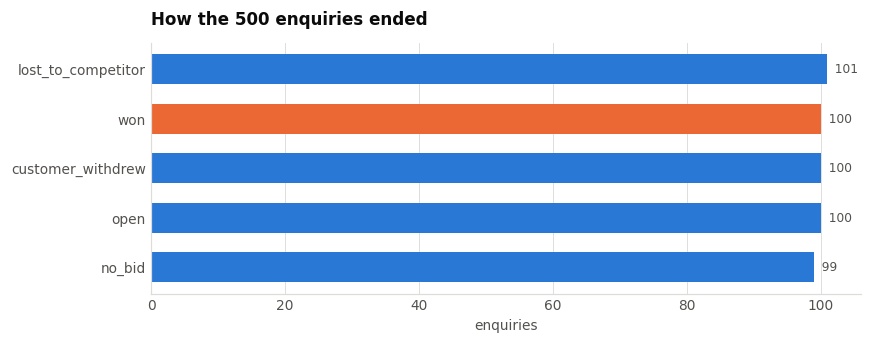

In [29]:
res = outcomes["result"].value_counts()
fig, ax = plt.subplots(figsize=(8, 3.2))
order_ = res.sort_values()
ax.barh(order_.index, order_.values, color=[ORANGE if i == "won" else BLUE for i in order_.index],
        height=0.6)
style(ax, "How the 500 enquiries ended", xlabel="enquiries", xgrid=True)
for y, v in enumerate(order_.values):
    ax.text(v, y, f"  {v}", va="center", fontsize=8, color=MUTED)
fig.tight_layout(); plt.show()

Five outcomes, almost exactly 100 of each.

A real pipeline is lumpy — some reasons dominate, win rates differ by channel and by product. A near-perfect fifth in every bucket is the signature of outcomes drawn at random from a list rather than arising from anything. Hold that thought for section 14.

In [30]:
print("quotes per enquiry:")
print(quotes.groupby("opportunity_id").size().value_counts().sort_index()
            .rename("enquiries").to_frame().to_string())
print()
print("negotiating rounds:")
print(quotes["round_number"].value_counts().sort_index().rename("quotes").to_frame().to_string())
print()
print("where a quoted price came from:")
print(quotes["price_origin"].value_counts().rename("quotes").to_frame().to_string())

quotes per enquiry:
   enquiries
1        159
2        182
3        159

negotiating rounds:
              quotes
round_number        
1                500
2                341
3                159

where a quoted price came from:
                 quotes
price_origin           
list                208
model_suggested     204
negotiated          204
random_test         194
contract            190


---
## 13. The price experiment hiding in the quotes

`Quote` carries a column called `test_offset`. It is the most valuable thing in this file, and it is easy to miss.

In [31]:
q = quotes.copy()
q["test_offset"] = pd.to_numeric(q["test_offset"], errors="coerce")
print("test_offset by price_origin:")
print(q.groupby("price_origin")["test_offset"]
       .agg(quotes="size", nonzero=lambda s: int((s.abs() > 1e-9).sum()),
            smallest="min", largest="max").round(4).to_string())

test_offset by price_origin:
                 quotes  nonzero  smallest  largest
price_origin                                       
contract            190        0     0.000   0.0000
list                208        0     0.000   0.0000
model_suggested     204        0     0.000   0.0000
negotiated          204        0     0.000   0.0000
random_test         194      194    -0.079   0.0789


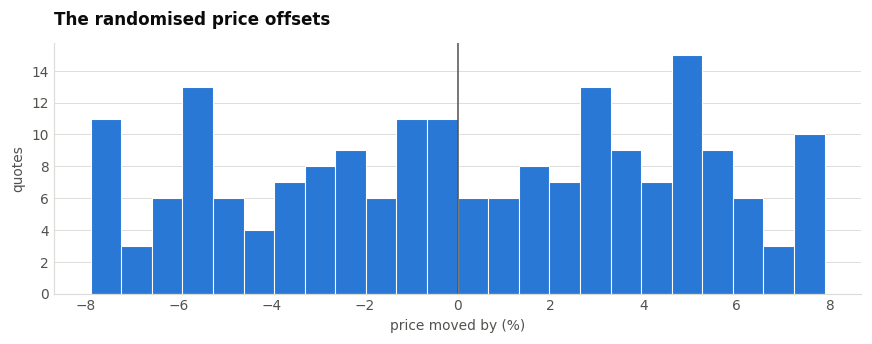

194 quotes had their price moved at random, by up to 7.9% either way.


In [32]:
arm = q[q["price_origin"] == "random_test"]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(arm["test_offset"] * 100, bins=24, color=BLUE, edgecolor="white", linewidth=0.7)
style(ax, "The randomised price offsets", xlabel="price moved by (%)", ylabel="quotes")
ax.axvline(0, color=MUTED, lw=1)
fig.tight_layout(); plt.show()

print(f"{len(arm)} quotes had their price moved at random, by up to "
      f"{arm['test_offset'].abs().max():.1%} either way.")

194 quotes were priced **at random**, up or down by as much as 8%.

That is a deliberate price experiment, and it is genuinely unusual — most commercial datasets contain only prices that somebody chose for a reason. When a salesperson discounts *because* they can tell a big order is coming, the data shows volume following discounts, and you cannot tell cause from consequence. Randomising the price breaks that link. It is the one design that makes "what happens if we raise the price" answerable rather than merely correlational.

So the obvious next question is what the experiment found.

---
## 14. Does anything respond to price?

Two independent ways to ask: did a higher quote lose more often, and did a higher price sell fewer units?

In [33]:
q2 = q.merge(outcomes[["opportunity_id", "result", "winning_quote_id"]],
             on="opportunity_id", how="left")
q2["won"] = (q2["quote_id"] == q2["winning_quote_id"]).astype(int)

arm = q2[q2["price_origin"] == "random_test"].copy()
arm["price moved by"] = pd.qcut(arm["test_offset"], 4, precision=1)
band = arm.groupby("price moved by", observed=True)["won"].agg(quotes="size", win_rate="mean")
print(band.to_string())

                quotes  win_rate
price moved by                  
(-0.18, -0.03]      49  0.102041
(-0.03, 0.003]      48  0.083333
(0.003, 0.04]       48  0.187500
(0.04, 0.08]        49  0.204082


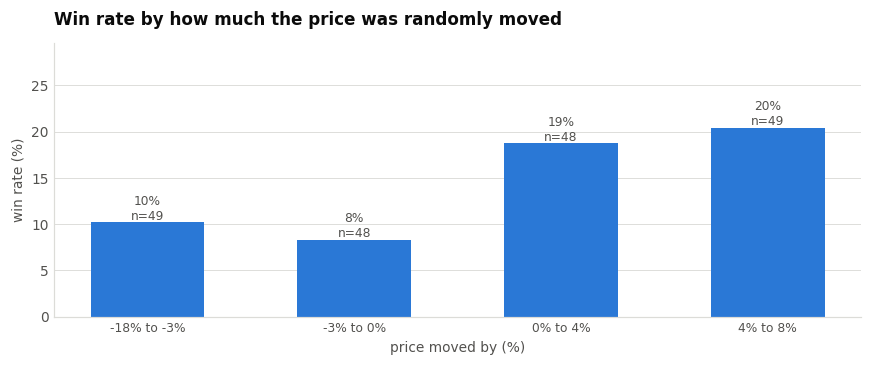

In [34]:
fig, ax = plt.subplots(figsize=(8, 3.4))
x = range(len(band))
ax.bar(x, band["win_rate"] * 100, color=BLUE, width=0.55)
style(ax, "Win rate by how much the price was randomly moved",
      xlabel="price moved by (%)", ylabel="win rate (%)")
ax.set_xticks(list(x))
ax.set_xticklabels([f"{i.left:.0%} to {i.right:.0%}" for i in band.index], fontsize=8)
for xi, v, n in zip(x, band["win_rate"] * 100, band["quotes"]):
    ax.text(xi, v, f"{v:.0f}%\nn={n}", ha="center", va="bottom", fontsize=8, color=MUTED)
ax.set_ylim(0, max(band["win_rate"] * 100) * 1.45)
fig.tight_layout(); plt.show()

The win rate goes **up** as the price goes up — 10% when discounted hardest, 20% when marked up hardest. Taken at face value that says customers prefer paying more.

It should not be taken at face value. With roughly 49 quotes per bar, bars this far apart are ordinary sampling noise:

In [35]:
from scipy import stats

won = arm.loc[arm.won == 1, "test_offset"]
lost = arm.loc[arm.won == 0, "test_offset"]
t, p = stats.ttest_ind(won, lost, equal_var=False)
print(f"mean price offset on quotes that WON : {won.mean():+.4f}   (n = {len(won)})")
print(f"mean price offset on quotes that LOST: {lost.mean():+.4f}   (n = {len(lost)})")
print(f"Welch t = {t:+.2f},  p = {p:.3f}")
print()

n, base = len(arm), arm["won"].mean()
smallest = 2.8 * math.sqrt(2 * base * (1 - base) / (n / 2))
print(f"With {n} quotes and a {base:.1%} base win rate, the smallest difference this")
print(f"experiment could reliably detect is about {smallest:.0%}.")
print("The entire spread across the four bars is about 10%.")
print()
print("So: no detectable effect, AND too small to have detected a realistic one.")

mean price offset on quotes that WON : +0.0158   (n = 28)
mean price offset on quotes that LOST: +0.0001   (n = 166)
Welch t = +1.77,  p = 0.084

With 194 quotes and a 14.4% base win rate, the smallest difference this
experiment could reliably detect is about 14%.
The entire spread across the four bars is about 10%.

So: no detectable effect, AND too small to have detected a realistic one.


There is a second problem, and this one is not about sample size:

In [36]:
wins = pd.crosstab(q2["price_origin"], q2["won"]).rename(columns={0: "lost", 1: "won"})
wins["win rate"] = (100 * wins["won"] / (wins["won"] + wins["lost"])).round(1)
print(wins.to_string())
print()
print(q2.groupby("round_number")["won"]
       .agg(quotes="size", won="sum", win_rate=lambda s: round(100 * s.mean(), 1)).to_string())

won              lost  won  win rate
price_origin                        
contract          153   37      19.5
list              173   35      16.8
model_suggested   204    0       0.0
negotiated        204    0       0.0
random_test       166   28      14.4

              quotes  won  win_rate
round_number                       
1                500   35       7.0
2                341   37      10.9
3                159   28      17.6


**408 quotes have a win rate of exactly zero.** Every `model_suggested` quote and every `negotiated` quote loses, without exception. Not rarely — never. Whatever produced this file decided the winner from a subset of quote types, so "the price came from the model" is a perfect predictor of losing.

And win rate climbs with negotiating round (7% → 11% → 18%) for a mechanical reason: reaching round three means the deal is still alive, and the winner is by construction one of the later quotes. Any model given these columns would seize on round number and price origin, and price would never get a look in.

Now the other direction — price against volume, on the order book:

In [37]:
Q = P.dropna(subset=["unit_price_recorded", "quantity", "list_price"]).copy()
Q = Q[(Q["unit_price_recorded"] > 0) & (Q["quantity"] > 0)]
Q["log_price"] = np.log(Q["unit_price_recorded"])
Q["log_quantity"] = np.log(Q["quantity"])

slope, intercept, r, pv, se = stats.linregress(Q["log_price"], Q["log_quantity"])
print(f"across the whole book: log(quantity) on log(price)")
print(f"  slope     {slope:+.3f}   (this is an elasticity: -1 means 1% dearer sells 1% fewer)")
print(f"  R-squared {r ** 2:.3f}")
print(f"  p-value   {pv:.3f}")
print()
print("but a slope across different products mostly measures that cheap things")
print("sell in bigger quantities than expensive things. Within one family:\n")

rows = []
for fam, g in Q.groupby("family"):
    if len(g) < 10:
        continue
    s, _, rr, pp, _ = stats.linregress(g["log_price"], g["log_quantity"])
    rows.append({"family": fam, "lines": len(g), "slope": round(s, 3),
                 "r_squared": round(rr ** 2, 3), "p_value": round(pp, 3)})
pd.DataFrame(rows)

across the whole book: log(quantity) on log(price)
  slope     +0.562   (this is an elasticity: -1 means 1% dearer sells 1% fewer)
  R-squared 0.035
  p-value   0.002

but a slope across different products mostly measures that cheap things
sell in bigger quantities than expensive things. Within one family:



,family,lines,slope,r_squared,p_value
0,FAM01,41,0.620,0.054,0.144
1,FAM02,46,0.509,0.027,0.278
2,FAM03,53,0.298,0.006,0.591
3,FAM04,61,0.941,0.133,0.004
4,FAM05,27,0.554,0.041,0.312
5,FAM06,34,-0.202,0.004,0.715


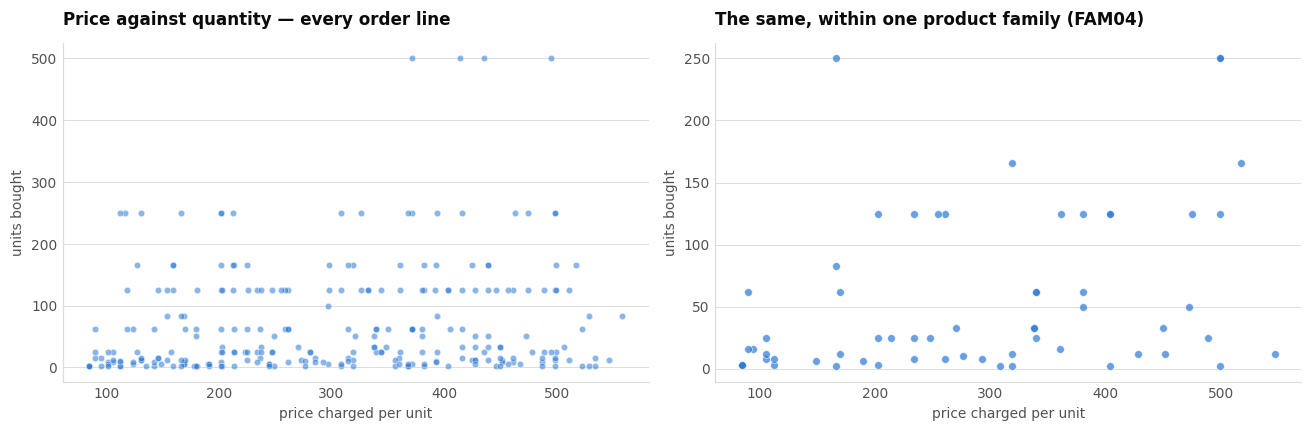

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(Q["unit_price_recorded"], Q["quantity"], s=18, color=BLUE,
                alpha=0.55, edgecolor="white", linewidth=0.5)
style(axes[0], "Price against quantity — every order line",
      xlabel="price charged per unit", ylabel="units bought")

fam = Q[Q["family"] == Q["family"].mode()[0]]
axes[1].scatter(fam["unit_price_recorded"], fam["quantity"], s=26, color=BLUE,
                alpha=0.7, edgecolor="white", linewidth=0.5)
style(axes[1], f"The same, within one product family ({Q['family'].mode()[0]})",
      xlabel="price charged per unit", ylabel="units bought")
fig.tight_layout(); plt.show()

No relationship, in either direction, by any cut.

Which closes the circle on section 9: **list prices never change in this file**, the only price variation is the discount granted on the day, and that variation carries no signal about volume. The randomised experiment that could have rescued this is too small to read and shows nothing anyway.